In [1]:
%matplotlib widget

In [2]:
import time
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xtquant import xtdata

import akshare as ak

d:\software\python\python38\lib\site-packages\akshare\__init__.py:2645: UserWarning: 为了支持更多特性，请将 Python 升级到 3.9 及以上版本！
  warnings.warn(


In [3]:
plt.rcParams['font.sans-serif'] = ['SimHei']

In [80]:
symbol = '000852.SH'

In [81]:
N = 50
M = 50
K = 50
X = 50
Y = 50

In [82]:
def ind_first(df_30):
    df_30.loc[:,'sum'] = df_30[['open', 'high', 'low', 'close']].sum(axis=1)
    df_30.loc[:,'AA'] = df_30['sum'] / 4
    df_30.loc[:,'BB'] = df_30['AA'].rolling(3, min_periods=1).mean()

    # SUM(IF(AA>REF(AA,1),AA*VOL,0),4)/SUM(IF(AA<REF(AA,1),AA*VOL,0),4)
    #df_cc = pd.DataFrame(np.where(df_30['AA'].diff(1).fillna(0) > 0, df_30['AA']*df_30['volume'], 0)).rolling(4, min_periods=1).sum() / pd.DataFrame(np.where(df_30['AA'].diff(1).fillna(0) < 0, df_30['AA']*df_30['volume'], 0)).rolling(4, min_periods=1).sum()
    df_cc = pd.DataFrame(np.where(df_30['AA'].diff(1).fillna(0) > 0, df_30['AA']*df_30['volume'], 1)).rolling(4, min_periods=1).sum() / pd.DataFrame(np.where(df_30['AA'].diff(1).fillna(0) < 0, df_30['AA']*df_30['volume'], 1)).rolling(4, min_periods=1).sum()
    df_cc = df_cc.rename(columns={0: 'CC'})
    df_cc.index = df_30.index
    df_30 = pd.concat([df_30, df_cc], axis=1)
    df_30.loc[:,'DD'] = 100-(100/(1 + df_30['CC'])).shift(1)
    
    df_30.loc[:,'A1'] = df_30['AA'].rolling(15, min_periods=1).max().fillna(0)
    df_30.loc[:,'A2'] = df_30['AA'].rolling(15, min_periods=1).min().fillna(0)
    df_30.loc[:,'A3'] = (df_30['A1'] - df_30['A2']).fillna(0)
    df_30.loc[:,'A4'] = ((df_30['AA'] - df_30['A2']) / df_30['A3']).ewm(span=2, adjust=False).mean() * 100
    
    df_30.loc[:,'B1'] = df_30['AA'].rolling(60, min_periods=1).max().fillna(0)
    df_30.loc[:,'B2'] = df_30['AA'].rolling(60, min_periods=1).min().fillna(0)
    df_30.loc[:,'B3'] = (df_30['B1'] - df_30['B2']).fillna(0)
    df_30.loc[:,'B4'] = ((df_30['AA'] - df_30['B2']) / df_30['B3']).ewm(span=2, adjust=False).mean() * 100
    
    df_30.loc[:,'C1'] = df_30['AA'].rolling(240, min_periods=1).max().fillna(0)
    df_30.loc[:,'C2'] = df_30['AA'].rolling(240, min_periods=1).min().fillna(0)
    df_30.loc[:,'C3'] = (df_30['C1'] - df_30['C2']).fillna(0)
    df_30.loc[:,'C4'] = ((df_30['AA'] - df_30['C2']) / df_30['C3']).ewm(span=2, adjust=False).mean() * 100
    #print(df_30.shape)
    #print(df_30[['CC', 'C1', 'C2', 'C3', 'C4']].head(30))
    return df_30


In [83]:
def ind_sec(df_5):
    
    df_5.loc[:,'B'] = 100 * ((df_5['close'] - df_5['high'].rolling(14).max()) / (df_5['high'].rolling(14).max() - df_5['low'].rolling(14).min())) + 100
    df_5.loc[:,'D'] = (100 * (df_5['close'] - df_5['high'].rolling(34).max()) / (df_5['high'].rolling(34).max() - df_5['low'].rolling(34).min())).ewm(span=4, adjust=False).mean() + 100
    df_5.loc[:,'A'] = (100 * (df_5['close'] - df_5['high'].rolling(34).max()) / (df_5['high'].rolling(34).max() - df_5['low'].rolling(34).min())).rolling(19, min_periods=1).mean() + 100
    
    return df_5

In [84]:
xtdata.download_history_data(symbol, period='5m', start_time='20200101')

In [85]:
data_5m = xtdata.get_market_data_ex([], [symbol], period='5m', count=-1)

In [86]:
xtdata.download_history_data(symbol, period='30m', start_time='20200101')

In [87]:
data_30m = xtdata.get_market_data_ex([], [symbol], period='30m', count=-1)

In [88]:
df_30m = ind_first(data_30m[symbol])

In [89]:
df_5m = ind_sec(data_5m[symbol])

In [90]:
df_30m['datetime'] = pd.to_datetime(df_30m['time'] / 1000, unit='s')

In [91]:
df_5m['datetime'] = pd.to_datetime(df_5m['time'] / 1000, unit='s')

In [92]:
df_30m.head(5)

,time,open,high,low,close,volume,amount,settelementPrice,openInterest,preClose,...,A4,B1,B2,B3,B4,C1,C2,C3,C4,datetime
20200102100000,1577930400000,5603.933,5629.871,5586.139,5629.871,44755391,4.359741e+10,0.0,0,5567.033,...,NaN,5612.45350,5612.4535,0.00000,NaN,5612.45350,5612.4535,0.00000,NaN,2020-01-02 02:00:00
20200102103000,1577932200000,5629.754,5648.953,5628.513,5648.318,26570356,2.620206e+10,0.0,0,5567.033,...,100.0,5638.88450,5612.4535,26.43100,100.0,5638.88450,5612.4535,26.43100,100.0,2020-01-02 02:30:00
20200102110000,1577934000000,5648.331,5664.312,5648.198,5656.652,21988759,2.204870e+10,0.0,0,5567.033,...,100.0,5654.37325,5612.4535,41.91975,100.0,5654.37325,5612.4535,41.91975,100.0,2020-01-02 03:00:00
20200102113000,1577935800000,5656.448,5670.769,5656.448,5662.584,16108717,1.661535e+10,0.0,0,5567.033,...,100.0,5661.56225,5612.4535,49.10875,100.0,5661.56225,5612.4535,49.10875,100.0,2020-01-02 03:30:00
20200102133000,1577943000000,5662.548,5673.019,5662.548,5669.878,16493705,1.654585e+10,0.0,0,5567.033,...,100.0,5666.99825,5612.4535,54.54475,100.0,5666.99825,5612.4535,54.54475,100.0,2020-01-02 05:30:00


In [93]:
# money = 10000000

In [94]:
def check(df_30, df_5):
    moneys = []
    money = 0
    buy_index = None
    close_flag = 0
    for i, index_30 in enumerate(df_30.index):
        # print(index)
        if df_30.shape[0] > i+1:
            start_5 = df_30.index[i]
            end_5 = df_30.index[i+1]
            if buy_index is None and df_30.loc[index_30]['C4'] <= N and df_30.loc[index_30]['B4'] <= M and df_30.loc[index_30]['A4'] >= K: # and df_30.loc[index_30]['A4'] > df_30.loc[index_30]['B4'] and df_30.loc[index_30]['B4'] > df_30.loc[index_30]['C4']:
                #print(index_30, start_5, end_5)
                for j, index_5 in enumerate(df_5[(df_5.index >= start_5) & (df_5.index < end_5)].index):
                    # print(df_5[df_5.index < index_5].iloc[-1])
                    # print('##########')
                    # print(df_5.loc[index_5])
                    # print('============================================')
                    # print(df_5[df_5.index <= index_5].tail(5))
                    # raise RuntimeError('sdfsdfsdf')
                    if df_5.loc[index_5]['D'] > 35 and df_5.loc[index_5]['D'] < 65 and df_5[df_5.index < index_5].iloc[-1]['D'] > df_5.loc[index_5]['D']:
                        buy_index = index_5
                        close_flag = 0
                        money += df_5.loc[index_5]['close']

                        print('卖出 开仓 %s %.02f %.02f' % (index_5, df_5.loc[index_5]['close'], money))
                        
                        with open('D:/code/python/fin/xxxxxxx.txt', 'a+', encoding='utf-8') as f:
                            f.write('%s %.02f' % (index_5, df_5.loc[index_5]['close']))
                        break

            close_flag = 0
            close_flags = []
            if buy_index is not None:
                _df_5 = df_5.loc[buy_index:end_5]
                for j, index_5 in enumerate(_df_5.index): # enumerate(_df_5[(_df_5.index >= start_5) & (_df_5.index < end_5)].index):
                    if j > 1 and _df_5[_df_5.index <= index_5].iloc[-3]['D'] > _df_5[_df_5.index <= index_5].iloc[-2]['D'] and _df_5[_df_5.index <= index_5].iloc[-2]['D'] < _df_5[_df_5.index <= index_5].iloc[-1]['D']:
                        close_flag += 1
                        close_flags.append(index_5)
                        
    
                    if close_flag >= 2:
                        with open('D:/code/python/fin/xxxxxxx.txt', 'a+', encoding='utf-8') as f:
                            for c in close_flags:
                                f.write(' %s' % (c))
                            
                        buy_index = None
                        close_flag = 0
                        money -= _df_5.loc[index_5]['close']

                        print('买入 平仓 %s %.02f %.02f' % (index_5, _df_5.loc[index_5]['close'], money))

                        with open('D:/code/python/fin/xxxxxxx.txt', 'a+', encoding='utf-8') as f:
                            f.write(' %s %.02f\n' % (index_5, _df_5.loc[index_5]['close']))

                        moneys.append(money)

                        break
                        
    return moneys

In [95]:
moneys = check(df_30m, df_5m)

卖出 开仓 20200205134000 5321.20 5321.20
买入 平仓 20200206094000 5383.47 -62.26
卖出 开仓 20200318132500 5707.90 5645.64
买入 平仓 20200318143000 5622.41 23.23
卖出 开仓 20200320105000 5628.24 5651.47
买入 平仓 20200320132500 5591.04 60.43
卖出 开仓 20200323094000 5554.37 5614.80
买入 平仓 20200323112500 5536.85 77.95
卖出 开仓 20200326094000 5618.14 5696.09
买入 平仓 20200326101500 5629.30 66.79
卖出 开仓 20200401133500 5449.71 5516.50
买入 平仓 20200401144000 5413.01 103.49
卖出 开仓 20200403144500 5505.00 5608.49
买入 平仓 20200407102500 5637.83 -29.34
卖出 开仓 20200428144000 5551.12 5521.79
买入 平仓 20200429101000 5591.06 -69.27
卖出 开仓 20200429112500 5561.77 5492.50
买入 平仓 20200429140500 5560.72 -68.22
卖出 开仓 20200914133000 6807.49 6739.28
买入 平仓 20200914142500 6809.21 -69.93
卖出 开仓 20200915094000 6828.67 6758.74
买入 平仓 20200915104500 6844.38 -85.64
卖出 开仓 20200915135500 6843.48 6757.84
买入 平仓 20200915145000 6876.95 -119.11
卖出 开仓 20200916095000 6844.85 6725.74
买入 平仓 20200916110000 6824.60 -98.86
卖出 开仓 20200917145500 6822.88 6724.02
买入 平仓 20200918095

In [96]:
ms = np.array(moneys)

In [97]:
# ms = ms - 10000000

d:\software\python\python38\lib\site-packages\ipympl\backend_nbagg.py:336: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  self.figure.savefig(buf, format='png', dpi='figure')


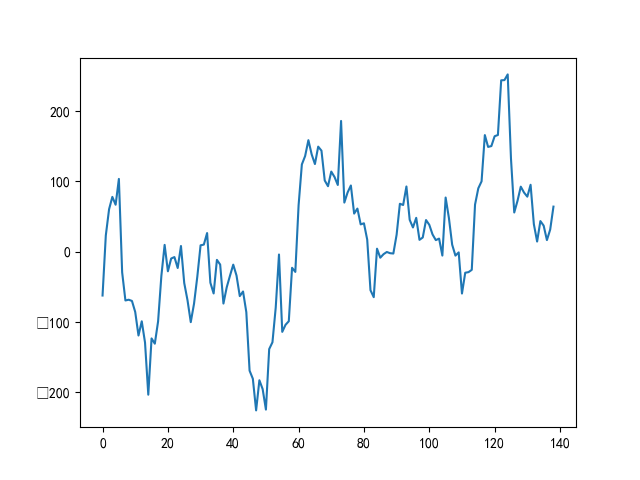

In [98]:
plt.close()
plt.plot(ms)

In [ ]:
moneys

In [7]:
# df_5m.tail(50)

In [69]:
dd = open('D:/code/python/fin/xxxxx 1.txt', 'r', encoding='utf-8').readlines()

In [100]:
ds = []
dates = []
for line in dd:
    sell_date, sell, buy_date, buy = line.strip().split()
    ds.append(float(sell) - float(buy))
    dates.append(buy_date)

In [103]:
ddddd = []
for i in range(len(ds)):
    ddddd.append([datetime.datetime.strptime(dates[i], '%Y%m%d%H%M%S'), np.sum(ds[:i+1])])

In [105]:
ddd_df = pd.DataFrame(ddddd)
ddd_df.index = ddd_df[0]

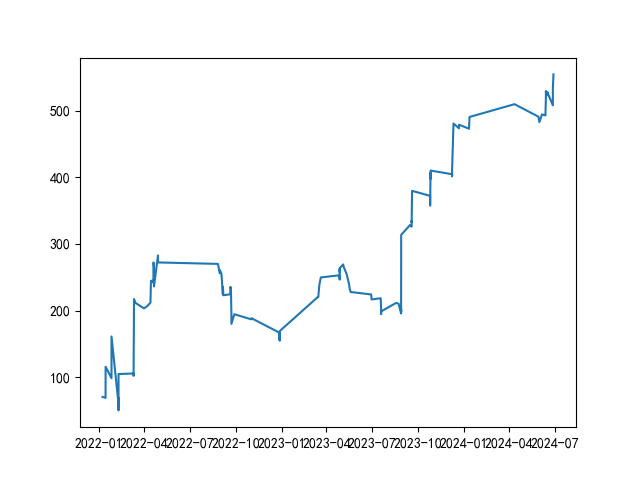

In [106]:
plt.close()
plt.plot(ddd_df[1])

In [90]:
d = xtdata.get_main_contract('IF00.IF') # 获取时间段内全部主力合约

In [91]:
d

'IF2407'

In [88]:
xtdata.get_main_contract?

Signature: xtdata.get_main_contract(code_market)
Docstring:
获取当前期货主力合约
:param code_market: (str)股票代码
:return: str
File:      d:\software\python\python38\lib\site-packages\xtquant\xtdata.py
Type:      function

In [ ]:
xtdata.get_market_data_ex([], [symbol], period=period, start_time='', end_time='', count=-1,dividend_type='none', fill_data=False)

In [ ]:
period = "historymaincontract" # 通过指定period参数 从gmd_ex接口获取历史主力合约信息
symbol = "IF00.IF" # 示例合约
xtdata.get_market_data_ex([], [symbol], period=period, start_time='', end_time='', count=-1,dividend_type='none', fill_data=False)

In [4]:
symbol = 'IM00.IF'

In [5]:
xtdata.download_history_data(symbol, period='1d', start_time='20190101')

***** xtdata连接成功 *****
服务信息: {'tag': 'sp3', 'version': '1.0'}
服务地址: 127.0.0.1:58610
数据路径: D:\tools\中航证券QMT实盘-交易端\bin.x64/../userdata_mini/datadir
设置xtdata.enable_hello = False可隐藏此消息



In [6]:
data = xtdata.get_market_data_ex([], [symbol], period='1d', count=-1)

In [7]:
df = data[symbol]

In [8]:
class a():
    pass
A = a()

In [9]:
A.buy_i = 0
A.sell_i = 0

A.buy_list = []
A.sell_list = []

for line in open('D:/code/python/fin/strategy3/定增.txt', 'r', encoding='utf-8'):
    # buy_date, symbol_code, symbol_name, inc_price, close_price, _, _, sell_date = line.strip().split()
    arr = line.strip().split()
    # print(buy_date, symbol, symbol_name, inc_price, close_price, sell_date)
    
    buy_date = datetime.datetime.strptime(arr[0], '%Y/%m/%d').strftime('%Y%m%d')
    A.buy_list.append([buy_date, arr[1]])

    if len(arr) > 7:
        sell_date = datetime.datetime.strptime(arr[7], '%Y/%m/%d').strftime('%Y%m%d')
        A.sell_list.append([sell_date, arr[1]])

A.buy_list.sort()
A.sell_list.sort()

In [67]:
# df.head(5)
xtdata.download_history_data('300858.SZ', period='1d', start_time='20220929')
_data = xtdata.get_market_data_ex([], ['300858.SZ'], period='1d', start_time='20220929', end_time='20220929', count=-1)

In [68]:
_data

{'300858.SZ':                    time  open   high   low  close  volume      amount  \
 20220929  1664380800000  24.3  24.85  24.1  24.24    8119  19900739.0   
 
           settelementPrice  openInterest  preClose  suspendFlag  
 20220929               0.0            15      24.0            0  }

In [10]:
# balance = 1000000000
# deposit_rate = 0.12

# call_positions = []
# # call_m = 0
# # call_ms = []

# put_positions = []
# # put_m = 0
# # put_ms = []

# call_put_ms = []

# A.buy_i = 0
# A.sell_i = 0

# for index, row in df.iterrows():
#     # print(row)

#     if len(A.buy_list) > A.buy_i:
#         buy_date, symbol_code = A.buy_list[A.buy_i]
#         if index > buy_date:
#             put_m += row.open
#             A.buy_i += 1

#             # print(buy_date)
#             xtdata.download_history_data(symbol_code.upper(), period='1d', start_time=str(buy_date))
#             _data = xtdata.get_market_data_ex([], [symbol_code.upper()], period='1d', start_time=str(buy_date), end_time=str(buy_date), count=-1)

#             amount = int(3000000 / (_data[symbol_code.upper()].iloc[0]['close'] * 100))
#             call_positions.append([symbol_code.upper(), amount])
#             call_m -= amount * _data[symbol_code.upper()].iloc[0]['close']
            
#             call_ms.append([datetime.datetime.strptime(index, '%Y%m%d'), call_m])
#             put_ms.append([datetime.datetime.strptime(index, '%Y%m%d'), put_m])
#             call_put_ms.append([datetime.datetime.strptime(index, '%Y%m%d'), call_m, put_m])
        
#             # print(index, buy_date, symbol_code, A.buy_i, 'buy')
#         else:
#             continue

#     if len(A.sell_list) > A.sell_i:
#         sell_date, symbol_code = A.sell_list[A.sell_i]
#         if index > sell_date:
#             put_m -= row.open
#             A.sell_i += 1

#             xtdata.download_history_data(symbol_code.upper(), period='1d', start_time=str(sell_date))
#             _data = xtdata.get_market_data_ex([], [symbol_code.upper()], period='1d', start_time=str(sell_date), end_time=str(sell_date), count=-1)
#             call_m += _data[symbol_code.upper()].iloc[0]['close'] * 200
            
#             call_ms.append([datetime.datetime.strptime(index, '%Y%m%d'), call_m])
#             put_ms.append([datetime.datetime.strptime(index, '%Y%m%d'), put_m])

#             call_put_ms.append([datetime.datetime.strptime(index, '%Y%m%d'), call_m, put_m])
#         else:
#             continue
    

# #print(m)

# # for (buy_date, symbol_code) in A.buy_list:
# #     #print(buy_date, symbol_code)

# #     m += df[buy_date:].iloc[1]['open']
    
# # print(m)

# # for (sell_date, symbol_code) in A.sell_list:
# #     #print(buy_date, symbol_code)

# #     m -= df[sell_date:].iloc[1]['open']
    
# # print(m)

In [17]:
# call_df = pd.DataFrame(call_ms)

In [18]:
# call_df.index = call_df[0]

In [19]:
# put_df = pd.DataFrame(put_ms)

In [20]:
# put_df.index = put_df[0]

In [21]:
# call_put_df = pd.DataFrame(call_put_ms)
# call_put_df.index = call_put_df[0]

In [22]:
# call_put_df[3] = call_put_df[1] + call_put_df[2]

In [23]:
# plt.close()
# plt.plot(call_put_df[1], label='定增')
# plt.plot(call_put_df[2], label='1000股指')
# plt.plot(call_put_df[3], label='合成')
# plt.legend()

In [11]:
df.head(5)

,time,open,high,low,close,volume,amount,settelementPrice,openInterest,preClose,suspendFlag
20220722,1658419200000,7050.0,7085.2,6857.0,6956.6,22153,4.934448e+09,6934.2,17517,0.0,0
20220725,1658678400000,6974.2,7015.8,6850.0,6878.6,22883,3.169970e+10,6885.8,18747,6956.6,0
20220726,1658764800000,6898.0,6994.0,6844.8,6991.0,19269,2.671201e+10,6964.4,20386,6878.6,0
20220727,1658851200000,6982.0,7074.4,6965.2,7066.2,19290,2.711399e+10,7059.4,21390,6991.0,0
20220728,1658937600000,7110.0,7171.4,7072.4,7119.0,22464,3.199381e+10,7112.4,24584,7066.2,0


In [12]:
def aaa(IM_money=350000, stock_money=3000000, deposit_rate = 0.12):
    balance = 1000000000
    balances = []
    #deposit_rate = 0.12
    
    call_positions = {}
    put_positions = {}
    
    
    A.buy_i = 0
    A.sell_i = 0
    
    for index, row in df.iterrows():
        # print(index, row)
    
        if len(A.buy_list) > A.buy_i:
            buy_date, symbol_code = A.buy_list[A.buy_i]
            if index > buy_date:
                # print(index, buy_date, symbol_code.upper(), A.buy_i, 'buy')
                
                A.buy_i += 1
                put_m = row.open
    
                xtdata.download_history_data(symbol_code.upper(), period='1d', start_time=str(buy_date))
                _data = xtdata.get_market_data_ex([], [symbol_code.upper()], period='1d', start_time=str(buy_date), end_time=str(buy_date), count=-1)
                call_m = _data[symbol_code.upper()].iloc[0]['close']
                
                call_amount = int(stock_money / (call_m * 100))
                call_positions[symbol_code.upper()] = [call_amount, index]
    
                put_amount = int(IM_money / (put_m * deposit_rate))
                put_positions[symbol_code.upper()] = [put_amount, index, put_m]

                balance -= ((call_amount * call_m * 100) + (put_amount * put_m * deposit_rate))
                # balance -= (call_amount * call_m * 100)
                # print(index, buy_date, symbol_code.upper(), A.buy_i, 'buy', (call_amount * call_m * 100), (put_amount * put_m))
    
        if len(A.sell_list) > A.sell_i:
            sell_date, symbol_code = A.sell_list[A.sell_i]
            if index > sell_date:
                # print(index, sell_date, symbol_code.upper(), A.sell_i, 'sell')
                
                A.sell_i += 1
                put_m = row.open

                sell_date_start = datetime.datetime.strptime(sell_date, '%Y%m%d') # .strftime('%Y%m%d')
                sell_date_end = sell_date_start + datetime.timedelta(days=5)
                sell_date_end = sell_date_end.strftime('%Y%m%d')
                
                # print(sell_date, symbol_code)
                xtdata.download_history_data(symbol_code.upper(), period='1d', start_time=str(sell_date))
                _data = xtdata.get_market_data_ex([], [symbol_code.upper()], period='1d', start_time=str(sell_date), end_time=str(sell_date_end), count=-1)
                call_m = _data[symbol_code.upper()].iloc[0]['close']
                
                [call_amount, _] = call_positions[symbol_code.upper()]
                del call_positions[symbol_code.upper()]
    
                [put_amount, _, put_open_price] = put_positions[symbol_code.upper()]
                del put_positions[symbol_code.upper()]
    
                balance += ((call_amount * call_m * 100) + (put_amount * put_open_price * deposit_rate) + (put_open_price - put_m) * put_amount)
                #balance += (call_amount * call_m * 100)
    
        amount = balance
        for symbol_code, [call_amount, _] in call_positions.items():
            _data = xtdata.get_market_data_ex([], [symbol_code.upper()], period='1d', start_time=index, end_time=index, count=-1)
            call_m = _data[symbol_code.upper()].iloc[0]['close']
    
            amount += call_amount * call_m * 100
            
        for symbol_code, [put_amount, _, put_open_price] in put_positions.items():
            put_m = row.open
    
            amount += (put_amount * put_open_price * deposit_rate) + (put_open_price - put_m) * put_amount
        
        balances.append([datetime.datetime.strptime(index, '%Y%m%d'), balance, amount])
    return balances

In [54]:
# for i in range(60, 95, 5):
#     im_money = i * 10000
#     bdf = pd.DataFrame(aaa(IM_money=im_money, stock_money=3000000, deposit_rate = 0.12))
#     bdf.index = bdf[0]

#     # if bdf.iloc[-1] > 1000000000:
#     #     print(i)

#     print(i, bdf.iloc[-1][2])

In [55]:
# xtdata.download_history_data('688625.sh'.upper(), period='1d', start_time=str(sell_date))
# _data = xtdata.get_market_data_ex([], ['688625.sh'.upper()], period='1d', start_time='20230102', end_time='20230103', count=-1)

In [56]:
# _data['688625.sh'.upper()]

In [13]:
im_money = 72 * 10000
bdf = pd.DataFrame(aaa(IM_money=im_money, stock_money=3000000, deposit_rate = 0.12))
bdf[3] = bdf[2] / 1000000000
bdf.index = bdf[0]

# if bdf.iloc[-1] > 1000000000:
#     print(i)

print(bdf.iloc[-1][2])

1016520808.5999994


In [199]:
#bdf = pd.DataFrame(aaa(IM_money=350000, stock_money=3000000, deposit_rate = 0.12))

In [200]:
#bdf.index = bdf[0]

In [15]:
#bdf[3].min()

In [14]:
bdf.tail(5)

,0,1,2,3
0,,,,
2024-06-25,2024-06-25,8.366309e+08,1.015730e+09,1.015730
2024-06-26,2024-06-26,8.366309e+08,1.020084e+09,1.020084
2024-06-27,2024-06-27,8.366309e+08,1.012636e+09,1.012636
2024-06-28,2024-06-28,8.366309e+08,1.018064e+09,1.018064
2024-07-01,2024-07-01,8.366309e+08,1.016521e+09,1.016521


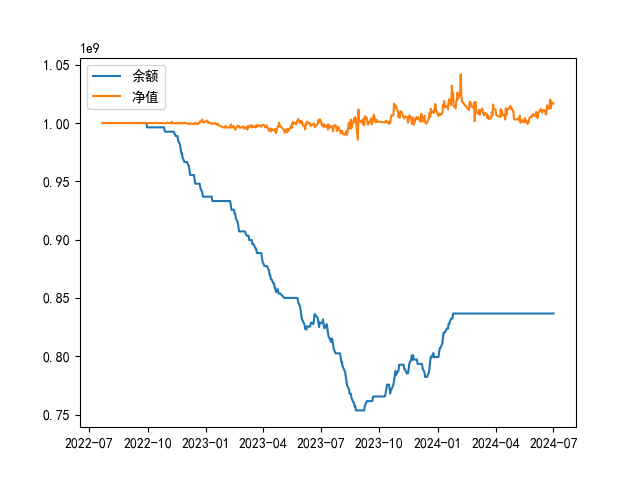

In [16]:
plt.close()
plt.plot(bdf[1], label='余额')
plt.plot(bdf[2], label='净值')
plt.legend()

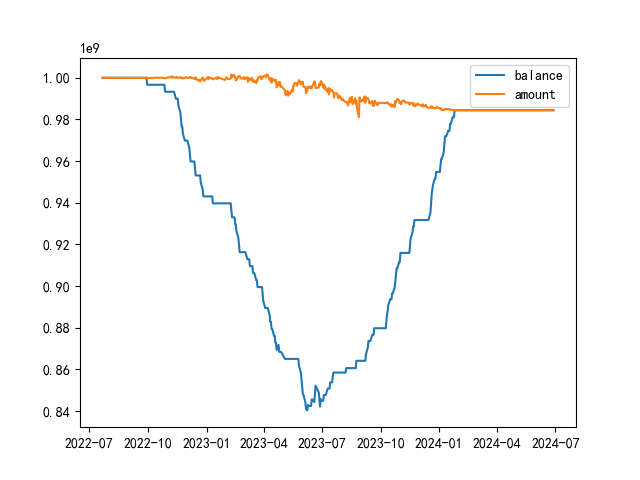

In [167]:
plt.close()
plt.plot(bdf[1], label='balance')
plt.plot(bdf[2], label='amount')
plt.legend()

In [80]:
ddd = pd.DataFrame(ms)

In [81]:
ddd.index = ddd[0]

In [82]:
ddd

,0,1
0,,
2022-09-30,2022-09-30,959.0
2022-10-28,2022-10-28,6296.2
2022-11-14,2022-11-14,5053.2
2022-11-18,2022-11-18,10589.8
2022-11-21,2022-11-21,9556.0
...,...,...
2024-01-10,2024-01-10,1321.6
2024-01-15,2024-01-15,-1716.4
2024-01-18,2024-01-18,-3613.4


In [83]:
ddd[1]

0
2022-09-30      959.0
2022-10-28     6296.2
2022-11-14     5053.2
2022-11-18    10589.8
2022-11-21     9556.0
               ...   
2024-01-10     1321.6
2024-01-15    -1716.4
2024-01-18    -3613.4
2024-01-22    -8046.2
2024-01-25   -11958.6
Name: 1, Length: 114, dtype: float64

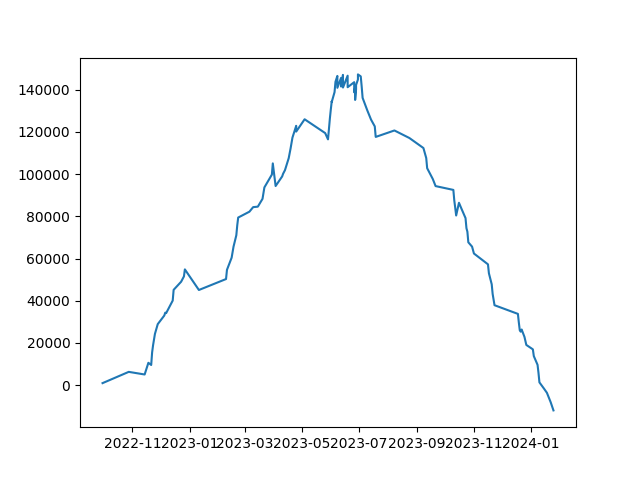

In [84]:
plt.close()
plt.plot(ddd[1])

In [ ]:
380308.60000000003
34537.4